# The maths behind Linear Regression

From "we want a smaller loss" to the two numbers that tell us how to get there:
$\frac{d\,\text{loss}}{da}$ and $\frac{d\,\text{loss}}{db}$.

# Setup

In [ ]:
%matplotlib widget

import matplotlib
import numpy as np
import matplotlib.pyplot as plt
import random
import matplotlib.colors as mcolors
from ipywidgets import interact, widgets, interactive, fixed, interact_manual
import random
import matplotlib.colors as mcolors
import time
import colorama
import pickle

with open("Teach_linear_regression.pkl", "rb") as f:
    (
        x, y, COEF_A, COEF_B,
        COEF_A_MIN, COEF_A_MAX,
        COEF_B_MIN, COEF_B_MAX,
        WORST_A_PARAM, WORST_B_PARAM,
        MIN_COST, MAX_COST,
        MIN_VALUE, MAX_VALUE, NB_ELEMENTS,
    ) = pickle.load(f)

In [ ]:
from matplotlib.offsetbox import AnchoredOffsetbox, DrawingArea, HPacker, TextArea, VPacker
from matplotlib.lines import Line2D


def get_df_by_dx(f, x, h):
    return (f(x + h) - f(x - h)) / (2 * h)


def _piece(text, color, fontsize):
    return TextArea(text, textprops=dict(color=color, fontsize=fontsize, weight="bold"))


def _fraction(top, top_color, bottom, bottom_color, fontsize, bar_color="purple"):
    """A fraction whose numerator and denominator carry different colours.

    Mathtext has no \\color, so a single $\\frac{..}{..}$ can only be one colour. The three
    pieces are packed as boxes instead, which is the only way to tie the numerator to the
    red line and the denominator to the blue one.
    """
    width = 0.62 * fontsize * max(len(top), len(bottom))
    bar = DrawingArea(width, 3, 0, 0)
    bar.add_artist(Line2D([0, width], [1.5, 1.5], color=bar_color, linewidth=1.5))
    return VPacker(children=[_piece(top, top_color, fontsize), bar,
                             _piece(bottom, bottom_color, fontsize)],
                   align="center", pad=0, sep=1)

def plot_function_with_derivative(f, x_point=1, h=0.5, plot_triangle=False, plot_df_by_dx=False, fig=None, ylim=(-2, 4), formula=None):
    # Generate points for plotting
    MINIMUM_Y = ylim[0]
    x = np.linspace(-1, 3, 1000)
    y = f(x)

    # Create the plot with twin axes
    if fig is None:
        fig, ax1 = plt.subplots(figsize=(12, 6))
    else:
        # Handed a figure: redraw inside it instead of opening another canvas.
        fig.clear()
        ax1 = fig.add_subplot()
    ax2 = ax1.twinx() if plot_df_by_dx else None

    if plot_df_by_dx:
        # Plot derivative on second axis
        df_by_dx = get_df_by_dx(f, x, h)
        # Split into positive and negative parts
        pos_mask = df_by_dx > 0
        neg_mask = df_by_dx < 0
        # A flat function has derivative 0, which is neither of the two. Lumping it in
        # with the negatives paints a line that does not move as "decreasing".
        zero_mask = df_by_dx == 0

        # print(f"{x.shape = }")
        # print(f"{df_by_dx.shape = }")
        # print(f"{x[pos_mask].shape = }")
        # print(f"{df_by_dx[pos_mask].shape = }")
        # print(f"{x[neg_mask].shape = }")
        # print(f"{df_by_dx[neg_mask].shape = }")

        # Plot positive values in green
        ax2.scatter(x[pos_mask], df_by_dx[pos_mask], c='g', marker='.', label="f'(x) > 0", alpha=0.25)
        # Plot negative values in red
        ax2.scatter(x[neg_mask], df_by_dx[neg_mask], c='r', marker='.', label="f'(x) < 0", alpha=0.25)

        # A constant derivative is constant only up to float noise. Left alone the twin
        # axis zooms into that noise and prints a 1e-12 offset, which reads as a bug.
        if np.ptp(df_by_dx) < 1e-6:
            centre = float(np.mean(df_by_dx))
            ax2.set_ylim(centre - 1, centre + 1)

        ax2.scatter(x[zero_mask], df_by_dx[zero_mask], c='gray', marker='.', label="f'(x) = 0", alpha=0.25)
        ax2.set_ylabel(r"$\frac{df(x)}{dx}$", color="g")
        ax2.tick_params(axis='y', labelcolor="g")

    # Plot main function on first axis
    ax1.plot(x, y, "black", label="f(x)", alpha=0.5)
    if formula is not None:
        # "black" at alpha 0.5 on white is exactly "gray", so the formula, the curve
        # and the left axis all read as the same thing.
        ax1.text(0.02, 0.96, rf"$f(x) = {formula}$", transform=ax1.transAxes,
                 va="top", color="gray", fontsize=13)
    # Calculate points for derivative visualization
    x_plus_h = x_point + h
    x_minus_h = x_point - h
    y_point = f(x_point)
    y_plus_h = f(x_plus_h)
    y_minus_h = f(x_minus_h)

    # Plot points
    ax1.plot(
        x_point, y_point, "X", color="orange", label=f"f({x_point:.2f})", markersize=10
    )
    ax1.plot([x_point, x_point], [MINIMUM_Y, y_point], color="orange", alpha=0.5)

    if plot_triangle:
        ax1.plot(x_point + h, y_plus_h, "+", color="gray", alpha=0.5, markersize=8)
        ax1.plot(x_point - h, y_minus_h, "+", color="gray", alpha=0.5, markersize=8)

        # Plot secant line through the two points
        x_line = np.array([x_point - h, x_point + h])
        y_line = np.array([y_minus_h, y_plus_h])
        ax1.plot(x_line, y_line, "-", color="purple", linewidth=2)

        top_horizontal_line_x = np.array([x_minus_h, x_plus_h])
        top_horizontal_line_y = np.array([y_plus_h, y_plus_h])

        left_vertical_line_x = np.array([x_minus_h, x_minus_h])
        left_vertical_line_y = np.array([y_minus_h, y_plus_h])

        h_minus_gray_line_x = np.array([x_minus_h, x_minus_h])
        h_minus_gray_line_y = np.array([-10, y_minus_h])

        h_plus_gray_line_x = np.array([x_plus_h, x_plus_h])
        h_plus_gray_line_y = np.array([-10, y_plus_h])

        # Add text annotations for dy and dx with their values
        dy = y_plus_h - y_minus_h
        dx = x_plus_h - x_minus_h
        derivative = dy / dx

        # Using matplotlib's text with math mode and custom colors
        ax1.text(0.02, 0.885, r"$\mathbf{dy} = " + f"{dy:.2f}$", transform=ax1.transAxes,
                 va="top", color="red", fontsize=12)
        ax1.text(
            0.02,
            0.818,
            r"$\mathbf{dx} = " + r" 2 \times h " + f" = {dx:.2f} " + "$",
            transform=ax1.transAxes,
            va="top",
            color="blue",
            fontsize=12,
        )

        # The ratio, with the top in the red of the dy line and the bottom in the blue of
        # the dx line, so the fraction and the drawing name the same two lengths.
        ratio = HPacker(
            children=[_fraction("dy", "red", "dx", "blue", 15),
                      _piece(" = ", "purple", 15),
                      _fraction(f"{dy:.2f}", "red", f"{dx:.2f}", "blue", 15),
                      _piece(f" = {derivative:.2f}", "purple", 15)],
            align="center", pad=0, sep=4)
        ax1.add_artist(AnchoredOffsetbox(
            loc="upper left", child=ratio, frameon=False, pad=0, borderpad=0,
            bbox_to_anchor=(0.02, 0.74), bbox_transform=ax1.transAxes))

        # Both values again, written on the lines they measure, so the fraction above can be
        # read straight off the drawing instead of matched up with a block of text.
        span = ylim[1] - ylim[0]
        # On a falling curve the horizontal leg is the BOTTOM of the triangle, so a label
        # above it lands inside, on top of the secant and the marker. Keep it outside.
        leg_on_top = dy >= 0
        ax1.text(
            x_minus_h + 0.03,
            y_plus_h + (0.015 * span if leg_on_top else -0.015 * span),
            r"$\mathbf{dx} = 2 h = " + f"{dx:.2f}$",
            color="blue",
            fontsize=12,
            ha="left",
            va="bottom" if leg_on_top else "top",
        )
        ax1.text(
            x_minus_h - 0.04,
            (y_minus_h + y_plus_h) / 2,
            r"$\mathbf{dy} = " + f"{dy:.2f}$",
            color="red",
            fontsize=12,
            ha="right",
            va="center",
        )
        ax1.plot(
            top_horizontal_line_x,
            top_horizontal_line_y,
            "-",
            color="blue",
            linewidth=2,
            label="$dx = 2 h$",
        )
        ax1.plot(
            left_vertical_line_x,
            left_vertical_line_y,
            "-",
            color="red",
            linewidth=2,
            label=r"$dy = f(x+h) - f(x-h)$",
        )
        ax1.plot(
            h_minus_gray_line_x,
            h_minus_gray_line_y,
            ":",
            color="gray",
            linewidth=2,
            label="x-h",
        )
        ax1.plot(
            h_plus_gray_line_x,
            h_plus_gray_line_y,
            ":",
            color="gray",
            linewidth=2,
            label="x+h",
        )

        ax1.text(x_plus_h + 0.05, MINIMUM_Y + 0.5, r"x+h", color="gray", fontsize=12)
        ax1.text(x_minus_h - 0.15, MINIMUM_Y + 0.5, r"x-h", color="gray", fontsize=12)

    ax1.grid(True)
    ax1.set_title(f"Function with Derivative Approximation (h={h:.2f})")
    ax1.set_xlabel("x")
    ax1.set_ylabel("f(x)", color="gray")
    ax1.tick_params(axis='y', labelcolor="gray")

    ax1.set_xlim(-1, 3)
    ax1.set_ylim(*ylim)


def chaotic_function(x):
    return (
        np.sin(5 * x**2) * np.cos(x / 2)
        + np.exp(-((x - 3) ** 2) / 10) * np.sin(5 * x)
        + 0.5 * np.tanh(x / 2)
    )

In [ ]:
# ---------------------------- Linear regression ----------------------------- #
def predict(x, a, b):
    return a * x + b

def get_cost(y, y_hat):
    return ((y - y_hat) ** 2).sum()

def get_gradients(x, y, a, b):
    """dloss/da and dloss/db for loss = sum((a*x + b - y)^2)."""
    error = predict(x, a, b) - y
    return (2 * error * x).sum(), (2 * error).sum()

# The cost surface, computed once: this is the landscape every later plot sits on.
A_GRID, B_GRID = np.meshgrid(np.linspace(COEF_A_MIN, COEF_A_MAX, 60),
                             np.linspace(COEF_B_MIN, COEF_B_MAX, 60))
COST_GRID = np.array([[get_cost(y, predict(x, a, b)) for a in A_GRID[0]] for b in B_GRID[:, 0]])
# Hue by height. A linear scale would spend its whole range on the walls (cost up to
# 1800) and paint the valley we care about in one flat colour, so compress the top end.
COST_NORM = mcolors.PowerNorm(0.4, vmin=COST_GRID.min(), vmax=MAX_COST)
# The left panel keeps fixed bounds: wide enough for any line the a and b sliders draw,
# so a diverging step leaves the frame instead of rescaling the data into a flat smear.
FIT_Y_MAX = COEF_A_MAX * x.max() + COEF_B_MAX
print(f"{NB_ELEMENTS} points | best a={COEF_A:.2f} b={COEF_B:.2f} | cost there = {get_cost(y, predict(x, COEF_A, COEF_B)):.0f}")

100 points | best a=1.78 b=3.05 | cost there = 35


# Hook

For our $a x + b$, we want to **minimize the loss**.

A really powerful tool would be $\dfrac{d\,\text{loss}}{da}$ and $\dfrac{d\,\text{loss}}{db}$. Why?

> Because a derivative tells us **how much the cost moves when we change a weight**.
>
> Computing it therefore tells us **how to update our weights**, and iterate towards a smaller loss.

interactive(children=(Checkbox(value=False, description='Cost surface'), FloatSlider(value=0.6, description='a…

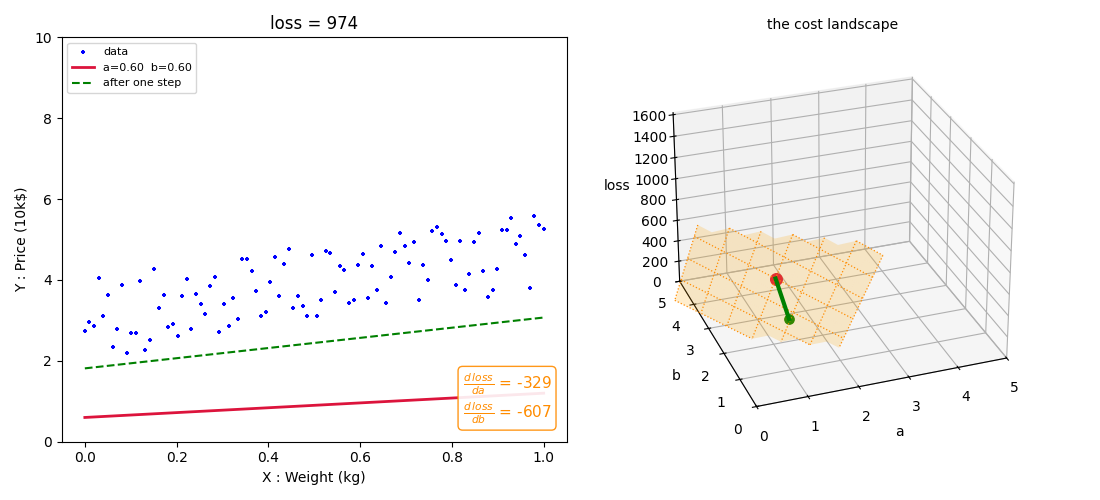

In [ ]:
# The figure is built ONCE here, outside the callback, and every update redraws into it.
fig = plt.figure(figsize=(11, 5))
ax_fit = fig.add_subplot(1, 2, 1)
ax_3d = fig.add_subplot(1, 2, 2, projection="3d")

@interact(
    show_surface=widgets.Checkbox(value=False, description="Cost surface"),
    a=widgets.FloatSlider(value=0.6, min=COEF_A_MIN, max=COEF_A_MAX, step=0.05, description="a:"),
    b=widgets.FloatSlider(value=0.6, min=COEF_B_MIN, max=COEF_B_MAX, step=0.05, description="b:"),
    learning_rate=widgets.FloatLogSlider(value=2e-3, base=10, min=-4, max=0, step=0.05,
                                         description="lr:", readout_format=".4f"),
)
def gradient_in_3d(show_surface, a, b, learning_rate):
    # Same pattern as notebook 2: reuse the figure, clear the axes. Creating a new
    # figure inside the callback is what stacks a fresh plot under every slider move.
    ax_fit.clear()
    ax_3d.clear()
    cost = get_cost(y, predict(x, a, b))
    d_a, d_b = get_gradients(x, y, a, b)

    # One gradient step: this is the arrow, and the whole point of the notebook.
    a_next, b_next = a - learning_rate * d_a, b - learning_rate * d_b
    y_next = predict(x, a_next, b_next)
    cost_next = get_cost(y, y_next)

    # Left: the line this (a, b) draws through the data.
    ax_fit.scatter(x, y, c="b", s=6, marker="+", label="data")
    ax_fit.plot(x, predict(x, a, b), c="crimson", lw=2, label=f"a={a:.2f}  b={b:.2f}")
    ax_fit.plot(x, y_next, c="green", lw=1.5, ls="--", label="after one step")
    ax_fit.set_xlabel("X : Weight (kg)"); ax_fit.set_ylabel("Y : Price (10k$)")
    ax_fit.set_title(f"loss = {cost:.0f}"); ax_fit.legend(loc="upper left", fontsize=8)
    ax_fit.set_ylim(0, FIT_Y_MAX)
    if y_next.min() > FIT_Y_MAX or y_next.max() < 0:
        # At the top of the lr slider one step overshoots by orders of magnitude. Say so,
        # rather than let the dashed line vanish with no explanation.
        ax_fit.text(0.5, 0.68, "the step took the line off the chart",
                    transform=ax_fit.transAxes, ha="center", va="center",
                    color="green", fontsize=12)

    # Right: the same (a, b) on the cost landscape.
    if show_surface:
        ax_3d.plot_surface(A_GRID, B_GRID, COST_GRID, cmap="viridis", norm=COST_NORM,
                           alpha=0.5, linewidth=0, antialiased=True)
        # The same dotted grid as the tangent plane, for the same reason: a smooth wash of
        # colour gives the eye nothing to measure curvature against, evenly spaced lines do.
        ax_3d.plot_wireframe(A_GRID, B_GRID, COST_GRID, rstride=10, cstride=10,
                             color="#263238", linewidths=0.7, linestyles=":", alpha=0.55)

    # The tangent plane: the local linear approximation the derivatives give us.
    # Kept small - the slope here is in the hundreds, so a wide patch would shoot off the axes.
    span, step = 1.5, 0.25
    ticks = np.arange(-span, span + step / 2, step)
    pa, pb = np.meshgrid(a + ticks, b + ticks)
    plane = cost + d_a * (pa - a) + d_b * (pb - b)
    plane[(plane < 0) | (plane > MAX_COST)] = np.nan      # mask, never distort
    ax_3d.plot_surface(pa, pb, plane, color="orange", alpha=0.2, linewidth=0, shade=False)
    # A dotted grid every 0.5 in a and in b. A flat orange wash gives the eye nothing to
    # measure the tilt against; evenly spaced lines do, and they stay readable through it.
    ax_3d.plot_wireframe(pa, pb, plane, rstride=2, cstride=2,
                         color="darkorange", linewidths=0.9, linestyles=":")

    # The step, drawn as a segment rather than a quiver: a 3D quiver with a z-component in the
    # hundreds escapes the axes box and reads as a bar across the whole figure.
    ax_3d.plot([a, a_next], [b, b_next], [cost, cost_next], c="green", lw=3, zorder=6)
    ax_3d.scatter(a_next, b_next, cost_next, c="green", s=45, marker="o", depthshade=False, zorder=7)
    ax_3d.scatter(a, b, cost, c="crimson", s=70, depthshade=False, zorder=8)

    ax_3d.set_xlim(COEF_A_MIN, COEF_A_MAX); ax_3d.set_ylim(COEF_B_MIN, COEF_B_MAX)
    ax_3d.set_zlim(0, MAX_COST)
    # Default view chosen so the tangent plane reads as a plane; drag to rotate.
    ax_3d.view_init(elev=28, azim=-110)
    ax_3d.set_xlabel("a"); ax_3d.set_ylabel("b")
    ax_3d.set_zlabel("loss", labelpad=8)
    ax_3d.set_title("the cost landscape", fontsize=10)
    ax_fit.text(0.97, 0.04, f"$\\frac{{d\\,loss}}{{da}}$ = {d_a:,.0f}\n"
                            f"$\\frac{{d\\,loss}}{{db}}$ = {d_b:,.0f}",
                transform=ax_fit.transAxes, fontsize=11, color="darkorange",
                ha="right", va="bottom",
                bbox=dict(boxstyle="round", fc="white", ec="darkorange", alpha=0.9))
    fig.tight_layout()
    fig.canvas.draw_idle()
    print(f"one step at lr={learning_rate:.4f}:  a {a:.2f} -> {a_next:.2f}   "
          f"b {b:.2f} -> {b_next:.2f}   loss {cost:.0f} -> {cost_next:.0f}")

The orange plane is what the two derivatives know: **the slope of the landscape right here**.
The green arrow is one step down it.

# But what is a derivative ?

Move the point, then shrink $h$.

interactive(children=(ToggleButtons(description='f(x):', index=1, options=('c', 'a·x', 'x²', 'chaotic'), value…

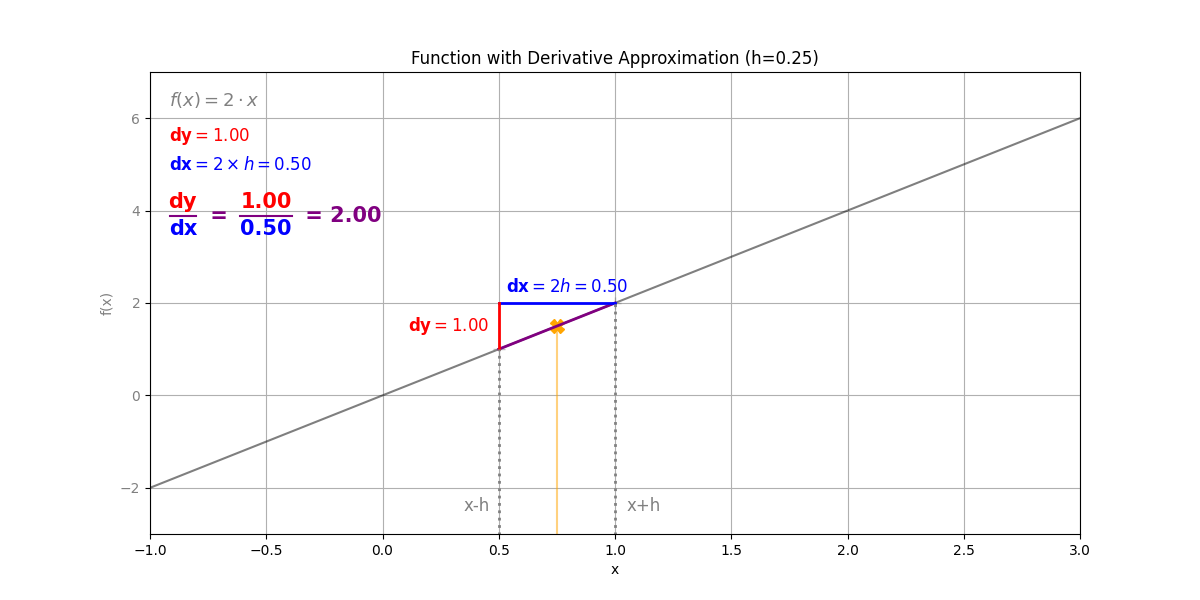

In [ ]:
# One figure for this demo too. The notebook stays on %matplotlib widget all the way
# through: switching to inline here makes the inline backend close every open figure
# at the end of the first cell that draws, which silently kills the 3D hook above.
fd_fig = plt.figure(figsize=(12, 6))

# The shapes the toolkit covers, each with the window that frames it over x in [-1, 3].
# A kink is worth a detour one day, the derivative does not exist at x = 1:
#     lambda x: np.where(x < 1, 2 * x, x / 2)
FUNCTIONS = {
    "c": (lambda x: 0 * x + 2, (0, 6), r"2"),   # 0 * x keeps the shape, scalar or array
    "a·x": (lambda x: 2 * x, (-3, 7), r"2 \cdot x"),
    "x²": (lambda x: x ** 2, (-1, 10), r"x^{2}"),
    "chaotic": (chaotic_function, (-2, 4),
                r"\sin(5x^{2})\cos(x/2)"
                r" + e^{-(x-3)^{2}/10}\sin(5x)"
                r" + 0.5\tanh(x/2)"),
}

@interact(
    function=widgets.ToggleButtons(
        options=list(FUNCTIONS),
        value="a·x",
        description="f(x):",
    ),
    x_point=widgets.FloatSlider(
        value=0.75,
        min=0.0,
        max=2.0,
        step=0.01,
        description="X:",
    ),
    h=widgets.FloatSlider(
        value=0.25,
        min=0.01,
        max=0.5,
        step=0.01,
        description="h:",
    ),
    plot_triangle=widgets.Checkbox(
        value=True,
        description="Plot triangle",
    ),
    plot_df_by_dx=widgets.Checkbox(
        value=False,
        description="Plot df/dx",
    ),
)
def interactive_derivative(function, x_point, h, plot_triangle, plot_df_by_dx):
    f, ylim, formula = FUNCTIONS[function]
    plot_function_with_derivative(f, x_point, h, plot_triangle, plot_df_by_dx,
                                  fig=fd_fig, ylim=ylim, formula=formula)
    fd_fig.canvas.draw_idle()

# AJOUTER L'ANGLE

### $\frac{df(x)}{dx} = \lim_{h \to 0} \frac{f(x+h) - f(x-h)}{2h}$

To be **infinitely precise**, $h$ needs to be **infinitely small**. That is what the limit says,
and what a formula gives us for free.

<details>
<summary><b>Formal demonstration: <i>f(x) = ax</i></b></summary>

$$
\begin{aligned}
\frac{d}{dx}[ax]
  &= \lim_{h \to 0} \frac{a(x+h) - a(x-h)}{2h} \\[4pt]
  &= \lim_{h \to 0} \frac{ax + ah - ax + ah}{2h} \\[4pt]
  &= \lim_{h \to 0} \frac{2ah}{2h} \\[4pt]
  &= a
\end{aligned}
$$

</details>

# The toolkit we need

![](./data/derivative_draw_0_high_level.jpg)

$$
\color{#56D4F5}{\text{loss}}
= \Big(\;
\color{#FFB454}{a} \cdot \color{#7EE787}{x}
+ \color{#FFB454}{b}
\;-\; \color{#7EE787}{y} \;\Big)^{2}
$$

Add, multiply, power, constant, and the chain rule.

| | rule | example | derivative |
|---|---|---|---|
| **Constant** | $\dfrac{d}{dx}[c] = 0$ | $f(x) = -4$ | $0$ |
| **Multiply** | $\dfrac{d}{dx}[ax] = a$ | $f(x) = 2x$ | $2$ |
| **Add** | $\dfrac{d}{dx}[ax+c] = a$ | $f(x) = 1 \cdot x+5$ | $1$ |
| **Power** | $\dfrac{d}{dx}[x^n] = n \cdot x^{n-1}$ | $f(x) = x^3$ | $3x^2$ |

<details>
<summary><b>Cheat sheet</b></summary>
<br>
<img src="./data/derivatives_cheat_sheet.png" alt="Derivatives cheat sheet" width="420">
</details>

### Where the other three come from

The same limit, applied to one shape at a time. Multiply is demonstrated just above, under the
limit itself.

<details>
<summary><b>Constant: <i>f(x) = c</i></b></summary>

$$
\begin{aligned}
\frac{d}{dx}[c]
  &= \lim_{h \to 0} \frac{c - c}{2h} \\[4pt]
  &= \lim_{h \to 0} \frac{0}{2h} \\[4pt]
  &= 0
\end{aligned}
$$

Moving $x$ changes nothing, so the top of the fraction is $0$ whatever $h$ you pick. This is the
`c` button on the demo above: $dy$ stays at $0.00$ however far you drag the slider.

</details>

<details>
<summary><b>Add: <i>f(x) = ax + c</i></b></summary>

$$
\begin{aligned}
\frac{d}{dx}[ax + c]
  &= \lim_{h \to 0} \frac{\big(a(x+h) + c\big) - \big(a(x-h) + c\big)}{2h} \\[4pt]
  &= \lim_{h \to 0} \frac{ax + ah + c - ax + ah - c}{2h} \\[4pt]
  &= \lim_{h \to 0} \frac{2ah}{2h} \\[4pt]
  &= a
\end{aligned}
$$

The $c$ cancels against itself, which is the whole statement: adding a constant slides the curve
up or down without tilting it, and a derivative only measures the tilt.

</details>

<details>
<summary><b>Power: <i>f(x) = x^n</i></b></summary>

Take $n = 2$ first, since that is the one our loss uses:

$$
\begin{aligned}
\frac{d}{dx}[x^{2}]
  &= \lim_{h \to 0} \frac{(x+h)^{2} - (x-h)^{2}}{2h} \\[4pt]
  &= \lim_{h \to 0} \frac{(x^{2} + 2xh + h^{2}) - (x^{2} - 2xh + h^{2})}{2h} \\[4pt]
  &= \lim_{h \to 0} \frac{4xh}{2h} \\[4pt]
  &= 2x
\end{aligned}
$$

Notice that we never had to take the limit: the $h$ cancelled on its own, so the answer was
already exact. That is why the demo above gives you $2x$ for any $h$ you choose.

For a general $n$, expanding $(x+h)^{n}$ and $(x-h)^{n}$ cancels every term carrying an even
power of $h$ and doubles the rest:

$$\frac{(x+h)^{n} - (x-h)^{n}}{2h}
= n\,x^{n-1} + \big(\text{terms carrying } h^{2} \text{ or more}\big)$$

Every leftover term still carries an $h^{2}$, so the limit wipes them out and leaves
$n \cdot x^{n-1}$.

</details>

## Chain rule

Because it lets us **derivate a complex formula by breaking it into simple ones**.

$$f(x) = \color{#FFB454}{5 \cdot} \color{#7EE787}{x^2} \color{#56D4F5}{+\, 3}$$

$$
\qquad
$$
$$
\color{#7EE787}{f_1(x) = x^2 = y_1}
$$
$$
\color{#FFB454}{f_2(y_1) = 5 \cdot y_1 = y_2}
$$
$$
\color{#56D4F5}{f_3(y_2) = 1 \cdot y_2 + 3 = y}
$$

$$
\qquad
$$
$$
x \rightarrow \color{#7EE787}{[\,f_1\,]} \rightarrow y_1
  \rightarrow \color{#FFB454}{[\,f_2\,]} \rightarrow y_2
  \rightarrow \color{#56D4F5}{[\,f_3\,]} \rightarrow y
$$

### Intuition

Every box asks the same question: **how does my output move when my input moves?**

$$\frac{d_{\text{out}}}{d_{\text{in}}}$$

And the change is carried along the chain, so the derivatives multiply, and the intermediates cancel:

$$
\frac{df(x)}{dx}
= \frac{\cancel{dy_1}}{dx} \cdot \frac{\bcancel{dy_2}}{\cancel{dy_1}} \cdot \frac{dy}{\bcancel{dy_2}}
$$

$$\boxed{\;\frac{d}{dx}\big[f(g(x))\big] = \frac{df}{dg} \cdot \frac{dg}{dx}\;}$$

<details>
<summary><b>Demonstration: solving the example</b></summary>

| piece | rule | derivative |
|---|---|---|
| $f_1(x) = x^2$ | $\frac{d}{dx}[x^n] = n x^{n-1}$ | $\frac{df_1}{dx} = 2x$ |
| $f_2(y_1) = 5 y_1$ | $\frac{d}{dx}[ax] = a$ | $\frac{df_2}{dy_1} = 5$ |
| $f_3(y_2) = y_2 + 3$ | $\frac{d}{dx}[x+c] = 1$ | $\frac{df_3}{dy_2} = 1$ |

$$\frac{df(x)}{dx} = 2x \cdot 5 \cdot 1 = 10x$$

</details>

# Applying it to our Linear Regression

$$
\color{#56D4F5}{\text{loss}}
= \Big(\;
\color{#FFB454}{a} \cdot \color{#7EE787}{x}
+ \color{#FFB454}{b}
\;-\; \color{#7EE787}{y} \;\Big)^{2}
$$

### GOAL : $\dfrac{d\,\color{#56D4F5}{\text{loss}}}{d\,\color{#FFB454}{a}}$ and $\dfrac{d\,\color{#56D4F5}{\text{loss}}}{d\,\color{#FFB454}{b}}$

### Break the problem down with the chain rule

![](./data/derivative_draw_1.jpg)

Each box of the drawing is one nested piece of the same formula:

$$
\color{#56D4F5}{\text{loss}} = \Bigg(
\overbrace{
  \underbrace{
    \underbrace{\color{#FFB454}{a} \cdot \color{#7EE787}{x}}_{\color{#56D4F5}{u}}
    + \color{#FFB454}{b}
  }_{\color{#56D4F5}{\hat{y}}}
  - \color{#7EE787}{y}
}^{\color{#56D4F5}{\Delta}}
\Bigg)^{2}
$$


For each step we can deduce $\frac{d\,\text{output}}{d\,\text{input}}$, and carry it on:

$$
\frac{d\text{loss}}{da} = \frac{d\text{loss}}{d\Delta} \cdot \frac{d\Delta}{d\hat{y}} \cdot \frac{d\hat{y}}{du} \cdot \frac{du}{da}
\qquad\qquad
\frac{d\text{loss}}{db} = \frac{d\text{loss}}{d\Delta} \cdot \frac{d\Delta}{d\hat{y}} \cdot \frac{d\hat{y}}{db}
$$

![](./data/derivative_draw_2.jpg)

### Carry the $d\,\text{loss}$ back through the chain

![](./data/derivative_draw_3.jpg)

### Can you fill the missing derivatives?

Take two minutes on the drawing below before opening the reminder.


<details>
<summary><b>The four rules, again</b></summary>

| | rule |
|---|---|
| Constant | $\frac{d}{dx}[c] = 0$ |
| Multiply | $\frac{d}{dx}[ax] = a$ |
| Add | $\frac{d}{dx}[x+c] = 1$ |
| Power | $\frac{d}{dx}[x^n] = n \cdot x^{n-1}$ |

</details>

### Fill in each derivative with the toolkit

![](./data/derivative_draw_4.jpg)
